In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import re

In [2]:
df = pd.read_csv('../resources/data_gabungan.csv')

print("=== Info Dataset ===")
df.info()

print("\n=== Jumlah Missing Values ===")
print(df.isnull().sum())

print("\n=== Distribusi Label ===")
print(df['Label Judi Online'].value_counts())
print(df['Label Toxic'].value_counts())

[Output tidak disertakan pada rilis publik. Hanya statistik agregat yang dipublikasikan; teks pesan pengguna, daftar frekuensi kata, dan identitas pengguna dihilangkan. Lihat 'Data & Content Policy' di README.]


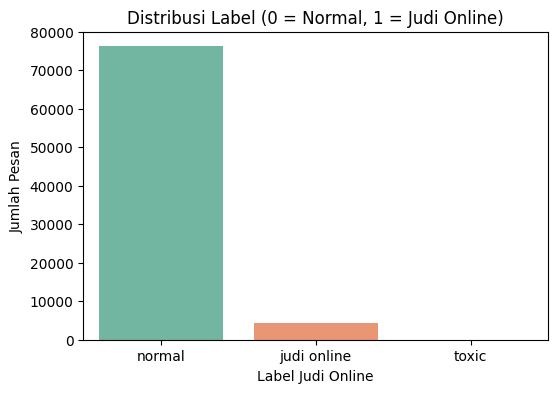

In [ ]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Label Judi Online', hue='Label Judi Online', palette='Set2', legend=False)
plt.title('Distribusi Label (0 = Normal, 1 = Judi Online)')
plt.xlabel('Label Judi Online')
plt.ylabel('Jumlah Pesan')
plt.show()

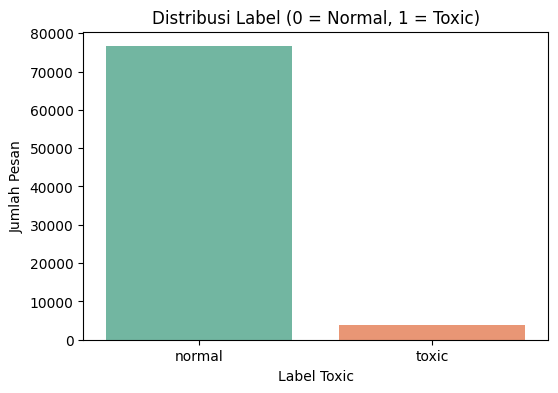

In [4]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Label Toxic', hue='Label Toxic', palette='Set2', legend=False)
plt.title('Distribusi Label (0 = Normal, 1 = Toxic)')
plt.xlabel('Label Toxic')
plt.ylabel('Jumlah Pesan')
plt.show()

In [5]:
top_authors_0 = df[df['Label Judi Online'] == 'normal']['Username'].value_counts().head(10)
top_authors_1 = df[df['Label Judi Online'] == 'judi online']['Username'].value_counts().head(10)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Pesan Normal
sns.barplot(x=top_authors_0.values, y=top_authors_0.index, ax=axes[0], color='skyblue')
axes[0].set_title('Top 10 Author - Pesan Normal (Label 0)')
axes[0].set_xlabel('Jumlah Pesan')

# Pesan Judi Online
sns.barplot(x=top_authors_1.values, y=top_authors_1.index, ax=axes[1], color='salmon')
axes[1].set_title('Top 10 Author - Spam Judi Online (Label 1)')
axes[1].set_xlabel('Jumlah Pesan')

plt.tight_layout()
plt.show()

In [6]:
top_authors_0 = df[df['Label Toxic'] == 'normal']['Username'].value_counts().head(10)
top_authors_1 = df[df['Label Toxic'] == 'toxic']['Username'].value_counts().head(10)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Pesan Normal
sns.barplot(x=top_authors_0.values, y=top_authors_0.index, ax=axes[0], color='skyblue')
axes[0].set_title('Top 10 Author - Pesan Normal (Label 0)')
axes[0].set_xlabel('Jumlah Pesan')

# Pesan Toxic
sns.barplot(x=top_authors_1.values, y=top_authors_1.index, ax=axes[1], color='salmon')
axes[1].set_title('Top 10 Author - Pesan Toxic (Label 1)')
axes[1].set_xlabel('Jumlah Pesan')

plt.tight_layout()
plt.show()

In [7]:
def get_top_words(text_series, top_n=20):
    words = ' '.join(text_series.dropna().astype(str).tolist()).lower()
    words = re.findall(r'\b\w+\b', words)
    return Counter(words).most_common(top_n)

# Ekstraksi untuk masing-masing kelas
top_words_0 = get_top_words(df[df['Label Judi Online'] == 'normal']['Pesan_Clean'])
top_words_1 = get_top_words(df[df['Label Judi Online'] == 'judi online']['Pesan_Clean'])

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Top kata pesan normal
words_0, counts_0 = zip(*top_words_0)
sns.barplot(x=list(counts_0), y=list(words_0), ax=axes[0], color='skyblue')
axes[0].set_title('Top 20 Kata - Pesan Normal')
axes[0].set_xlabel('Frekuensi')

# Top kata spam judi online
words_1, counts_1 = zip(*top_words_1)
sns.barplot(x=list(counts_1), y=list(words_1), ax=axes[1], color='salmon')
axes[1].set_title('Top 20 Kata - Spam Judi Online')
axes[1].set_xlabel('Frekuensi')

plt.tight_layout()
plt.show()

In [8]:
def get_top_words(text_series, top_n=20):
    words = ' '.join(text_series.dropna().astype(str).tolist()).lower()
    words = re.findall(r'\b\w+\b', words)
    return Counter(words).most_common(top_n)

# Ekstraksi untuk masing-masing kelas
top_words_0 = get_top_words(df[df['Label Toxic'] == 'normal']['Pesan_Clean'])
top_words_1 = get_top_words(df[df['Label Toxic'] == 'toxic']['Pesan_Clean'])

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Top kata pesan normal
words_0, counts_0 = zip(*top_words_0)
sns.barplot(x=list(counts_0), y=list(words_0), ax=axes[0], color='skyblue')
axes[0].set_title('Top 20 Kata - Pesan Normal')
axes[0].set_xlabel('Frekuensi')

# Top kata spam judi online
words_1, counts_1 = zip(*top_words_1)
sns.barplot(x=list(counts_1), y=list(words_1), ax=axes[1], color='salmon')
axes[1].set_title('Top 20 Kata - Pesan Toxic')
axes[1].set_xlabel('Frekuensi')

plt.tight_layout()
plt.show()

In [9]:
from sklearn.feature_extraction.text import CountVectorizer

# Ekstrak Frasa N-gram
def get_top_phrases(text_series, ngram_range=(2, 3), top_n=20):
    valid_text = text_series.dropna().astype(str)
    
    vectorizer = CountVectorizer(ngram_range=ngram_range)
    X = vectorizer.fit_transform(valid_text)
    
    phrases = vectorizer.get_feature_names_out()
    frequencies = X.sum(axis=0).A1
    
    phrase_freq = list(zip(phrases, frequencies))
    phrase_freq.sort(key=lambda x: x[1], reverse=True)
    
    return phrase_freq[:top_n]

# Ekstraksi
top_phrases_0 = get_top_phrases(df[df['Label Judi Online'] == 'normal']['Pesan_Clean'], ngram_range=(2, 3), top_n=20)
top_phrases_1 = get_top_phrases(df[df['Label Judi Online'] == 'judi online']['Pesan_Clean'], ngram_range=(2, 3), top_n=20)

# Visualisasi
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

phrases_0, counts_0 = zip(*top_phrases_0)
sns.barplot(x=list(counts_0), y=list(phrases_0), ax=axes[0], color='skyblue')
axes[0].set_title('Top 20 Frasa (2-3 Kata) - Pesan Normal')
axes[0].set_xlabel('Frekuensi')
axes[0].set_ylabel('Frasa')

phrases_1, counts_1 = zip(*top_phrases_1)
sns.barplot(x=list(counts_1), y=list(phrases_1), ax=axes[1], color='salmon')
axes[1].set_title('Top 20 Frasa (2-3 Kata) - Spam Judi Online')
axes[1].set_xlabel('Frekuensi')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

In [10]:
from sklearn.feature_extraction.text import CountVectorizer

# Ekstrak Frasa N-gram
def get_top_phrases(text_series, ngram_range=(2, 3), top_n=20):
    valid_text = text_series.dropna().astype(str)
    
    vectorizer = CountVectorizer(ngram_range=ngram_range)
    X = vectorizer.fit_transform(valid_text)
    
    phrases = vectorizer.get_feature_names_out()
    frequencies = X.sum(axis=0).A1
    
    phrase_freq = list(zip(phrases, frequencies))
    phrase_freq.sort(key=lambda x: x[1], reverse=True)
    
    return phrase_freq[:top_n]

# Ekstraksi
top_phrases_0 = get_top_phrases(df[df['Label Toxic'] == 'normal']['Pesan_Clean'], ngram_range=(2, 3), top_n=20)
top_phrases_1 = get_top_phrases(df[df['Label Toxic'] == 'toxic']['Pesan_Clean'], ngram_range=(2, 3), top_n=20)

# Visualisasi
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

phrases_0, counts_0 = zip(*top_phrases_0)
sns.barplot(x=list(counts_0), y=list(phrases_0), ax=axes[0], color='skyblue')
axes[0].set_title('Top 20 Frasa (2-3 Kata) - Pesan Normal')
axes[0].set_xlabel('Frekuensi')
axes[0].set_ylabel('Frasa')

phrases_1, counts_1 = zip(*top_phrases_1)
sns.barplot(x=list(counts_1), y=list(phrases_1), ax=axes[1], color='salmon')
axes[1].set_title('Top 20 Frasa (2-3 Kata) - Pesan Toxic')
axes[1].set_xlabel('Frekuensi')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

In [11]:
# Mengambil 20 contoh acak
normal_msgs = df[df['Label Judi Online'] == 'normal']['Pesan'].dropna().sample(10, random_state=42).tolist()
judi_msgs = df[df['Label Judi Online'] == 'judi online']['Pesan'].dropna().sample(10, random_state=42).tolist()

# Menampilkan Pesan Normal
print("=== 10 CONTOH PESAN NORMAL (Label 0) ===")
for i, msg in enumerate(normal_msgs, 1):
    print(f"{i}. {msg}")

# Menampilkan Pesan Judi Online
print("\n=== 10 CONTOH SPAM JUDI ONLINE (Label 1) ===")
for i, msg in enumerate(judi_msgs, 1):
    print(f"{i}. {msg}")

[Output tidak disertakan pada rilis publik. Hanya statistik agregat yang dipublikasikan; teks pesan pengguna, daftar frekuensi kata, dan identitas pengguna dihilangkan. Lihat 'Data & Content Policy' di README.]


In [12]:
# Mengambil 20 contoh acak
normal_msgs = df[df['Label Toxic'] == 'normal']['Pesan'].dropna().sample(10, random_state=42).tolist()
judi_msgs = df[df['Label Toxic'] == 'toxic']['Pesan'].dropna().sample(10, random_state=42).tolist()

# Menampilkan Pesan Normal
print("=== 10 CONTOH PESAN NORMAL (Label 0) ===")
for i, msg in enumerate(normal_msgs, 1):
    print(f"{i}. {msg}")

# Menampilkan Pesan Toxic
print("\n=== 10 CONTOH PESAN TOXIC (Label 1) ===")
for i, msg in enumerate(judi_msgs, 1):
    print(f"{i}. {msg}")

[Output tidak disertakan pada rilis publik. Hanya statistik agregat yang dipublikasikan; teks pesan pengguna, daftar frekuensi kata, dan identitas pengguna dihilangkan. Lihat 'Data & Content Policy' di README.]
